# Serving Retrieval Evaluation

This notebook freezes 12 development queries and captures the same hybrid candidates and source passages used by `app_hybrid.py`. All review dates in the existing serving corpus are allowed for this descriptive IR evaluation.

**Primary unit:** query/restaurant pair
**Target:** relevance supported by the returned passages/reviews and structured snapshot metadata
**Primary cutoff:** 10 restaurants, taking the top 10 of the 30 returned candidates 

These queries reuse development themes, making sure to cover an array of different subjects.

In [1]:
import json
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / 'src'))

from recommender.index_hybrid import GemmaEmbedder, HybridIndex, load_settings

OUT = ROOT / 'data/processed/evaluation/serving_relevance_v1'
OUT.mkdir(parents=True, exist_ok=True)

cfg = load_settings(ROOT)
app_cfg = yaml.safe_load((ROOT / 'config_app.yaml').read_text())

manifest = json.loads((ROOT / 'index/hybrid/serving/active.json').read_text())
if manifest['mode'] != 'serving' or manifest['trial']:
    raise ValueError("This evaluation requires a completed full serving index.")
    
display(pd.Series({key: manifest[key] for key in ['run', 'restaurants', 'reviews', 'passages']}))

c:\Users\davis\Documents\VCCode Repos\Restaurant-Recommendation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


run            7fb3efd8a91547738f6bf2d5b0eeea01
restaurants                                3527
reviews                                  511311
passages                                 636498
dtype: object

## Frozen Queries

Filters are explicit inputs from the UI and not inferred from any wording. The combined price/outdoor request exercises shared eligibility, missing metadata cannot pass. The impossible location query checks unsupported results, technically nothing should be returned for it. These have been used for evaluation so do not edit them.

In [2]:
queries = pd.DataFrame([
    ('app_01', 'spicy Thai curry', 'cuisine', None, False, False, False),
    ('app_02', 'wood fired pizza', 'cuisine', None, False, False, False),
    ('app_03', 'quiet place for a date night', 'atmosphere', None, False, False, False),
    ('app_04', 'vegan dinner with several options', 'dietary', None, False, False, False),
    ('app_05', 'gluten free pizza options', 'dietary', None, False, False, False),
    ('app_06', 'quick affordable lunch', 'service', 2, False, False, False),
    ('app_07', 'takeout dinner delivered', 'service', None, True, True, False),
    ('app_08', 'inexpensive lunch with outdoor seating', 'conjunction', 2, False, False, True),
    ('app_09', 'spicy vegetarian curry for takeout', 'conjunction', None, False, True, False),
    ('app_10', 'dinner without live music', 'negation', None, False, False, False),
    ('app_11', 'comida vegetariana', 'multilingual', None, False, False, False),
    ('app_12', 'a restaurant on the moon', 'impossible_location', None, False, False, False)
], columns=['query_id', 'query', 'intent', 'max_price', 'delivery', 'takeout', 'outdoor'])

queries['max_price'] = queries.max_price.astype('Int64')
query_file = OUT / 'queries.csv'

if not query_file.exists():
    queries.to_csv(query_file, index=False)
    
display(queries)

,query_id,query,intent,max_price,delivery,takeout,outdoor
0,app_01,spicy Thai curry,cuisine,<NA>,False,False,False
1,app_02,wood fired pizza,cuisine,<NA>,False,False,False
2,app_03,quiet place for a date night,atmosphere,<NA>,False,False,False
3,app_04,vegan dinner with several options,dietary,<NA>,False,False,False
4,app_05,gluten free pizza options,dietary,<NA>,False,False,False
5,app_06,quick affordable lunch,service,2,False,False,False
6,app_07,takeout dinner delivered,service,<NA>,True,True,False
7,app_08,inexpensive lunch with outdoor seating,conjunction,2,False,False,True
8,app_09,spicy vegetarian curry for takeout,conjunction,<NA>,False,True,False
9,app_10,dinner without live music,negation,<NA>,False,False,False


## Capture Rankings and Evidence

Keep up to 30 candidates per query to make a depth-30 judgment pool. Top 10 are
the primary review queue. Preserve exact returned passages and deduplicate each
restaurant's evidence by passage ID, as the app does. Capture only once; reruns
reuse frozen outputs. Query timing excludes model/index loading and LLM generation,
includes the first cold query, and is only one observation per query.

In [3]:
capture_file = OUT / 'capture.json'

if capture_file.exists():
    capture = json.loads(capture_file.read_text())
    if capture['build'] != manifest['run'] or capture['settings'] != cfg:
        raise ValueError("The frozen capture uses a different build or settings. Start a new evaluation version.")
    if capture['queries'] != json.loads(queries.to_json(orient='records')):
        raise ValueError("The queries differ from the frozen capture. Start a new evaluation version.")
else:
    started = perf_counter()

    embedder = GemmaEmbedder(cfg, device=app_cfg['device'], batch_size=app_cfg['embedding_batch_size'])
    index = HybridIndex(ROOT, cfg, embedder, mode='serving')

    load_seconds = perf_counter() - started
    catalog = index.catalog.set_index('business_id')

    captures = []
    for row in queries.to_dict('records'):
        filters = {key: row[key] for key in ['delivery', 'takeout', 'outdoor']}
        filters['max_price'] = None if pd.isna(row['max_price']) else int(row['max_price'])

        started = perf_counter()
        hits = index.search(row['query'], **filters)
        elapsed = perf_counter() - started

        for hit in hits:
            hit['evidence'] = list({item['passage_id']: item for item in hit['evidence']}.values())
            info = catalog.loc[hit['business_id']]
            hit['metadata'] = json.loads(info.to_json())

        captures.append({'query_id': row['query_id'], 'seconds': elapsed, 'hits': hits})
        print(f"{row['query_id']}: {len(hits)} candidates, {elapsed:.3f} seconds", flush=True)

    capture = {
        'build': manifest['run'],
        'settings': cfg,
        'queries': json.loads(queries.to_json(orient='records')),
        'load_seconds': load_seconds,
        'results': captures
    }
    capture_file.write_text(json.dumps(capture, indent=2), encoding='utf-8')

rows = []
for result in capture['results']:
    query = queries.set_index('query_id').loc[result['query_id']]

    for rank, hit in enumerate(result['hits'], 1):
        rows.append({
            'query_id': result['query_id'],
            'query': query['query'],
            'intent': query['intent'],
            'business_id': hit['business_id'],
            'rank': rank,
            'primary_top10': rank <= 10,
            'score': hit['score'],
            'name': hit['metadata']['name'],
            'metadata': json.dumps(hit['metadata'], ensure_ascii=False),
            'evidence': json.dumps(hit['evidence'], ensure_ascii=False)
        })

rankings = pd.DataFrame(rows)
rankings.to_csv(OUT / 'rankings.csv', index=False)

timings = pd.DataFrame([
    {'query_id': result['query_id'], 'seconds': result['seconds'], 'candidates': len(result['hits'])}
    for result in capture['results']
])
timings.to_csv(OUT / 'query_timings.csv', index=False)

display(timings)
display(rankings.groupby('intent').agg(candidates=('business_id', 'size'), queries=('query_id', 'nunique')))

,query_id,seconds,candidates
0,app_01,32.099850,30
1,app_02,10.587360,30
2,app_03,6.153327,30
3,app_04,6.122282,30
4,app_05,10.517284,30
5,app_06,4.853948,30
6,app_07,4.232748,30
7,app_08,3.139810,30
8,app_09,5.409532,30
9,app_10,5.660329,30


,candidates,queries
intent,,
atmosphere,30,1
conjunction,60,2
cuisine,60,2
dietary,60,2
impossible_location,30,1
multilingual,30,1
negation,30,1
service,60,2


## Judgment Queue and Metric Rules

The supplied metadata and exact returned passages were used for relevance grading. For grading, no evidence mention meant unknown rather than proof of absence. Negative sentiment alone does not negate topical relevance. Dietary labels never prove allergen safety. Contradictory evidence was preserved.

| Grade | Rule |
| --- | --- |
| 0 | Irrelevant or explicit essential constraint failure |
| 1 | Partial match or insufficient support for an essential requirement |
| 2 | Supported useful match with only minor uncertainty on softer preferences |
| 3 | Strong direct support for every material request component |

constraint_pass was recorded as pass/fail/unknown/not_applicable and evidence_status as supported/partial/contradicted/insufficient/mixed, with source review IDs and rationale. The app_12 location requirement cannot be met
so its returned scores could not be considered as confidence.

Precision@10 uses grade ≥2 and ten slots including missing results. NDCG@10 is normalized discounted cumulative gain at 10 (at the top 10 ranks). It is a metric used for ranking and recommender systems, like this! It is the ratio of the discounted cumulative gain (the actual model score) vs the ideal discounted cumulative gain (the maximum possible score if results were sorted in the optimal order). The score ranges from 0 (no relevance at all) to 1 (perfect ranking). I used the exponential variant of the formula which is:

$$
\text{NDCG@10} = \frac{\text{DCG@10}}{\text{IDCG@10}} \\[10pt]
\text{DCG@10} = \sum_{i=1}^{10} \frac{2^{g_i}−1}{\log_2(i+1)} \\[10pt]
\text{IDCG@10} = \sum_{i=1}^{10} \frac{2^{g^*_i}−1}{\log_2(i+1)}
$$

where $g_i$ is the grade for that index/rank and $g^*_i$ is the ideal grade at that rank. The top ten ideal and actual results are chosen from the full 30 candidate pool, so the ranking has to both select the most relevant results and correctly rank them. This is a single system depth 30 denominator which is restricted and may be optimistic, it is not full catalog NDCG so results aren't a full direct metric of the entire app. But they are at least representative. Pooled recall is optional and uses only this judged pool.

In [4]:
judgment_file = OUT / 'judgments.csv'

if not judgment_file.exists():
    judgments = rankings[['query_id', 'query', 'intent', 'business_id', 'name', 'metadata', 'evidence']].copy()
    for column in ['relevance_grade', 'constraint_pass', 'evidence_status', 'source_review_ids', 'rationale', 'label_source', 'annotator']:
        judgments[column] = ''

    judgments = judgments.sample(frac=1, random_state=42).reset_index(drop=True)
    judgments.to_csv(judgment_file, index=False)

judgments = pd.read_csv(judgment_file)

primary = rankings.loc[rankings.primary_top10, ['query_id', 'business_id']]
primary.merge(judgments, on=['query_id', 'business_id']).sample(frac=1, random_state=42).to_csv(OUT / 'top10_review_queue.csv', index=False)

display(pd.Series({
    'frozen_queries': len(queries),
    'primary_pairs': len(primary),
    'pool_pairs': len(judgments),
    'graded_pairs': judgments.relevance_grade.notna().sum(),
    'ungraded_pairs': judgments.relevance_grade.isna().sum()
}))
print("No relevance metrics are reported until the required judgments are completed.")

frozen_queries     12
primary_pairs     120
pool_pairs        360
graded_pairs      360
ungraded_pairs      0
dtype: int64

No relevance metrics are reported until the required judgments are completed.


## Ranking Metrics

Join judgments to the frozen rankings by query ID and business ID, requiring complete and valid grades for every ranked candidate before calculating scores. A relevant result has grade ≥2. Precision@10 divides by ten slots, including missing results.

Following the intial pilot rule, NDCG and pooled recall exclude queries with no pooled grade ≥2, even if some grade 1 evidence exists. Precision includes all frozen queries. Restricted pool recall@10 = relevant top ten results / relevant depth 30 results. Average query scores equally (macro averages).

In [5]:
keys = ['query_id', 'business_id']
judgments = pd.read_csv(OUT / 'judgments.csv')
rankings = pd.read_csv(OUT / 'rankings.csv')

scored = rankings.merge(
    judgments[keys + ['relevance_grade', 'constraint_pass', 'evidence_status']],
    on=keys,
    how='left',
    validate='one_to_one'
)

if not scored.relevance_grade.isin([0, 1, 2, 3]).all():
    raise ValueError("Every ranked candidate needs a completed relevance grade from 0 to 3 before calculating metrics.")

query_metrics = []
for query in queries.to_dict('records'):
    pool = scored.loc[scored.query_id.eq(query['query_id'])].sort_values('rank')
    top = pool.head(10)
    grades = top.relevance_grade.to_numpy()
    ideal = np.sort(pool.relevance_grade.to_numpy())[::-1][:10]
    dcg = ((2**grades - 1) / np.log2(np.arange(len(grades)) + 2)).sum()
    idcg = ((2**ideal - 1) / np.log2(np.arange(len(ideal)) + 2)).sum()
    relevant_pool = int(pool.relevance_grade.ge(2).sum())
    relevant_top = int(top.relevance_grade.ge(2).sum())
    ndcg = dcg / idcg if relevant_pool else np.nan
    query_metrics.append({
        'query_id': query['query_id'],
        'query': query['query'],
        'intent': query['intent'],
        'judged_pool': len(pool),
        'supported_pool': relevant_pool,
        'supported_top10': relevant_top,
        'precision_at_10': relevant_top / 10,
        'ndcg_at_10': ndcg,
        'pooled_recall_at_10': relevant_top / relevant_pool if relevant_pool else np.nan,
        'constraint_fail_top10': int(top.constraint_pass.eq('fail').sum()),
        'constraint_unknown_top10': int(top.constraint_pass.eq('unknown').sum()),
        'mixed_evidence_top10': int(top.evidence_status.eq('mixed').sum())
    })

per_query = pd.DataFrame(query_metrics)
summary = pd.DataFrame([
    {
        'metric': metric,
        'macro_mean': per_query[metric].mean(),
        'queries_scored': int(per_query[metric].notna().sum()),
        'queries_total': len(queries)
    }
    for metric in ['precision_at_10', 'ndcg_at_10', 'pooled_recall_at_10']
])

per_query.to_csv(OUT / 'per_query_metrics.csv', index=False)
summary.to_csv(OUT / 'metrics_summary.csv', index=False)

display(summary.round(4))
display(per_query.round(4))
print("Queries without a supported match in the judged pool:")
display(per_query.loc[per_query.supported_pool.eq(0), ['query_id', 'query']])

,metric,macro_mean,queries_scored,queries_total
0,precision_at_10,0.6250,12,12
1,ndcg_at_10,0.6690,11,12
2,pooled_recall_at_10,0.3379,11,12


,query_id,query,intent,judged_pool,supported_pool,supported_top10,precision_at_10,ndcg_at_10,pooled_recall_at_10,constraint_fail_top10,constraint_unknown_top10,mixed_evidence_top10
0,app_01,spicy Thai curry,cuisine,30,22,7,0.7,0.6259,0.3182,0,3,1
1,app_02,wood fired pizza,cuisine,30,24,9,0.9,0.9076,0.3750,0,1,1
2,app_03,quiet place for a date night,atmosphere,30,18,6,0.6,0.6153,0.3333,0,4,4
3,app_04,vegan dinner with several options,dietary,30,21,6,0.6,0.4790,0.2857,0,4,0
4,app_05,gluten free pizza options,dietary,30,22,9,0.9,0.7584,0.4091,0,1,2
5,app_06,quick affordable lunch,service,30,23,9,0.9,0.8913,0.3913,0,1,0
6,app_07,takeout dinner delivered,service,30,25,9,0.9,0.8822,0.3600,0,1,1
7,app_08,inexpensive lunch with outdoor seating,conjunction,30,28,10,1.0,0.9513,0.3571,0,0,0
8,app_09,spicy vegetarian curry for takeout,conjunction,30,7,4,0.4,0.5384,0.5714,0,6,0
9,app_10,dinner without live music,negation,30,3,0,0.0,0.0000,0.0000,10,0,0


Queries without a supported match in the judged pool:


,query_id,query
11,app_12,a restaurant on the moon


## Evidence and Filter Diagnostics

Semantic constraint status comes from the human labeled judgments, not an outside source of truth. Check strict structured filters separately against the captured metadata, only for queries with an active filter. Report unknown
and mixed evidence, rather than hiding those results behind a ranking average. The impossible location query should ideally be rejected by an application policy, retrieval alone still returns candidates and is not an abstention mechanism.

In [6]:
top10 = scored.loc[scored['rank'].le(10)]

checks = []
for query in queries.to_dict('records'):
    active = pd.notna(query['max_price']) or any(query[key] for key in ['delivery', 'takeout', 'outdoor'])
    if not active:
        continue

    for row in top10.loc[top10.query_id.eq(query['query_id'])].to_dict('records'):
        meta = json.loads(row['metadata'])
        passed = True
        if pd.notna(query['max_price']):
            passed = meta['price'] is not None and meta['price'] <= query['max_price']

        for required, column in [('delivery', 'delivery'), ('takeout', 'takeout'), ('outdoor', 'outdoor_seating')]:
            if query[required]:
                passed = passed and meta[column] is True

        checks.append({'query_id': query['query_id'], 'business_id': row['business_id'], 'passed': passed})

filter_checks = pd.DataFrame(checks)
diagnostics = pd.Series({
    'judged_pairs': len(judgments),
    'pool_label_coverage': scored.relevance_grade.notna().mean(),
    'primary_pairs': len(top10),
    'primary_label_coverage': top10.relevance_grade.notna().mean(),
    'structured_filter_pairs_checked': len(filter_checks),
    'structured_filter_pass_rate': filter_checks.passed.mean(),
    'semantic_constraint_fail_rate_top10': top10.constraint_pass.eq('fail').mean(),
    'semantic_constraint_unknown_rate_top10': top10.constraint_pass.eq('unknown').mean(),
    'mixed_evidence_rate_top10': top10.evidence_status.eq('mixed').mean()
})

diagnostics.to_csv(OUT / 'diagnostics.csv', header=['value'])
filter_checks.to_csv(OUT / 'structured_filter_checks.csv', index=False)
display(diagnostics)

error_examples = top10.loc[
    top10.constraint_pass.isin(['fail', 'unknown']),
    keys + ['rank', 'name', 'relevance_grade', 'constraint_pass', 'evidence_status']
].merge(judgments[keys + ['rationale']], on=keys, validate='one_to_one')

error_examples.to_csv(OUT / 'top10_error_analysis.csv', index=False)
display(error_examples.groupby('query_id').head(2))

judged_pairs                              360.000000
pool_label_coverage                         1.000000
primary_pairs                             120.000000
primary_label_coverage                      1.000000
structured_filter_pairs_checked            40.000000
structured_filter_pass_rate                 1.000000
semantic_constraint_fail_rate_top10         0.166667
semantic_constraint_unknown_rate_top10      0.208333
mixed_evidence_rate_top10                   0.075000
dtype: float64

,query_id,business_id,rank,name,relevance_grade,constraint_pass,evidence_status,rationale
0,app_01,bLJP0fVgscuUQy0hE_CRXA,5,Xiandu Thai,1,unknown,mixed,One red-curry report says it was not spicy des...
1,app_01,v6tFMx_fKBcfiBagKb_EIg,8,Daleng Restaurant,1,unknown,partial,"Curry is mentioned, but the stated excessive s..."
3,app_02,fN12ywQpLXQ93bpwe1N_Ww,10,Pietro's Coal Oven Pizzeria,1,unknown,mixed,One passage explicitly calls the pizza coal-fi...
4,app_03,cOXc8c85Ms6dMEAJazLXHQ,3,McGillin's Olde Ale House,1,unknown,mixed,One review explicitly rejects the loud crowded...
5,app_03,OXFCsM7_GkJ9KC93_UIbuw,4,PTG Catering,1,unknown,mixed,The review calls the setting quiet and suitabl...
8,app_04,rOspf7E1Y8YAbVXTZyl-tQ,1,Cedar Point Bar and Kitchen,1,unknown,partial,"Dinner and vegan hot wings are explicit, but s..."
9,app_04,dG-gZOWzn8iO1Rvv_fbXxA,2,Silk City Diner & Lounge,1,unknown,partial,Duplicate review text describes dinner with ve...
12,app_05,SOsjW1JARmtHUFtpFlp8rw,6,Snap Custom Pizza - Center City,1,unknown,mixed,One reviewer praises the gluten-free pizza; an...
13,app_06,vuE1iseFrgNPumUEfHIZZQ,10,JJ Thai Cuisine,1,unknown,partial,"A cheap lunch special is established, but neit..."
14,app_07,swcfmflnWlhnbvPOHvPq_A,5,Chabaa Thai Bistro,1,unknown,mixed,"Takeout meals are explicit, but the review wis..."


## Query Level View and Reporting Limits

Each query is shown alone rather than overall average. Dietary conjunction and negative requirements can behave differently from simple cuisine matching. The single system depth 30 ideal ranking is restricted and potentially optimistic. These metrics evaluate retrieval, not LLM answer faithfulness or user satisfaction.

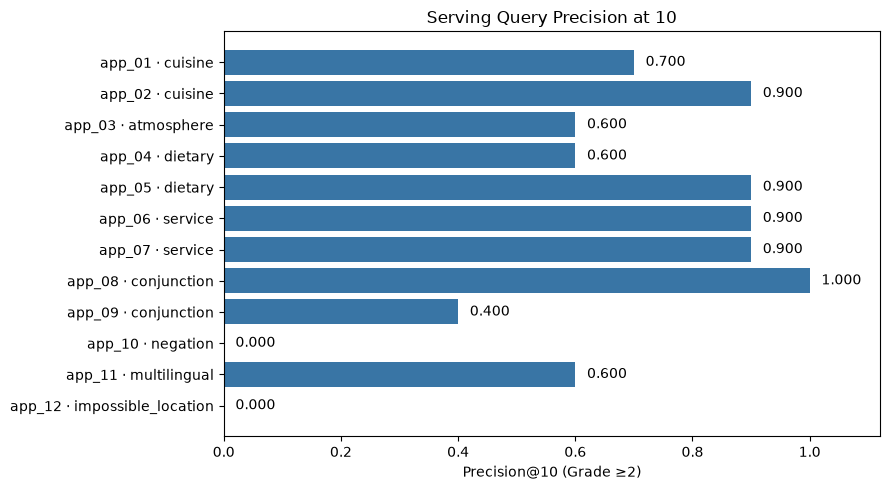

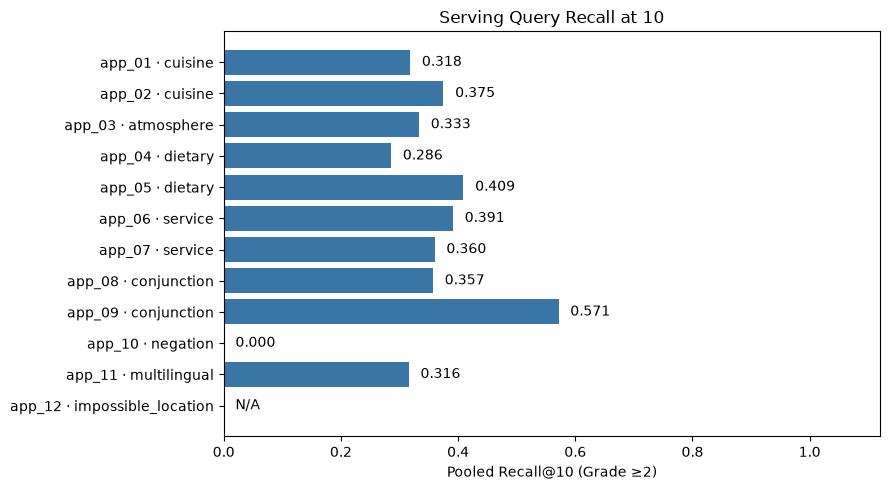

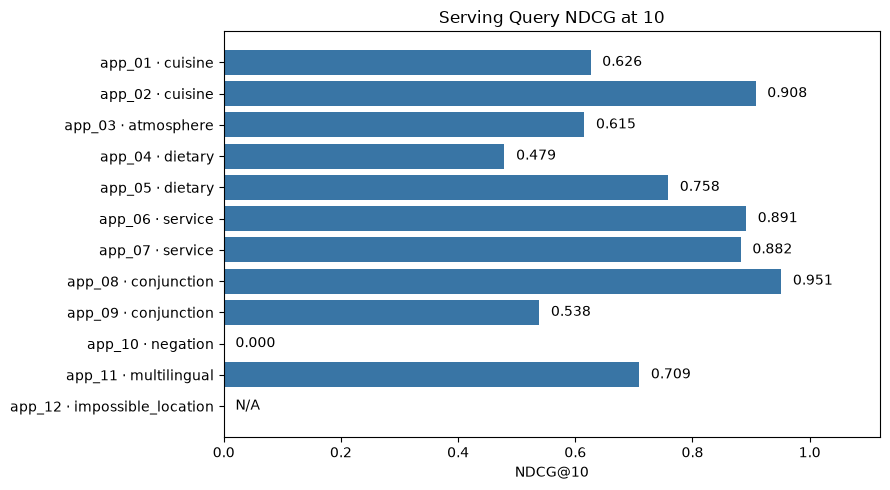

In [12]:
plots = [
    ('precision_at_10', "Precision@10 (Grade ≥2)", 'precision_by_query.png', 'Serving Query Precision at 10'),
    ('pooled_recall_at_10', "Pooled Recall@10 (Grade ≥2)", 'recall_by_query.png', 'Serving Query Recall at 10'),
    ('ndcg_at_10', "NDCG@10", 'ndcg_by_query.png', 'Serving Query NDCG at 10')
]

for metric, label, filename, title in plots:
    fig, ax = plt.subplots(figsize=(9, 5))
    positions = np.arange(len(per_query))
    values = per_query[metric]

    ax.barh(positions, values.fillna(0), color='#3975a5')
    ax.set_yticks(positions, per_query.query_id + ' · ' + per_query.intent)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.12)
    ax.set_xlabel(label)
    ax.set_title(title)

    for position, value in zip(positions, values, strict=True):
        text = "N/A" if np.isnan(value) else f"{value:.3f}"
        location = 0.02 if np.isnan(value) else value + 0.02
        ax.text(location, position, text, va='center')

    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=160, bbox_inches='tight')
    plt.show()